# Sistema de Recomendação

In [1]:
#Imports
import os
os.environ['SPARK_HOME'] = r'C:\Users\galgu\Downloads\spark-3.4.1-bin-hadoop3'
import findspark
findspark.init()
from pyspark.sql import SparkSession
import pyspark.sql.functions as f

In [2]:
spark = SparkSession.builder\
                    .master('local[*]')\
                    .appName('Recomendacao com Spark')\
                    .getOrCreate()

In [3]:
dados = spark.\
        read.\
        csv('dados_musicas.csv', header=True, sep=';', inferSchema=True)

## Exploração de dados

In [4]:
dados.show()

+------------------+----+------------+--------------+------------------+-----------+------------------+--------+--------------------+--------------------+---+--------+-------------------+----+--------------------+----------+-----------+------------------+--------------------+
|           valence|year|acousticness|       artists|      danceability|duration_ms|            energy|explicit|                  id|    instrumentalness|key|liveness|           loudness|mode|                name|popularity|speechiness|             tempo|        artists_song|
+------------------+----+------------+--------------+------------------+-----------+------------------+--------+--------------------+--------------------+---+--------+-------------------+----+--------------------+----------+-----------+------------------+--------------------+
|             0.285|2000|     0.00239|      Coldplay|             0.429|     266773|0.6609999999999999|       0|3AJwUDP919kvQ9Qco...|             1.21E-4| 11|   0.234|  

In [5]:
dados.printSchema()

root
 |-- valence: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- artists: string (nullable = true)
 |-- danceability: double (nullable = true)
 |-- duration_ms: integer (nullable = true)
 |-- energy: double (nullable = true)
 |-- explicit: integer (nullable = true)
 |-- id: string (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- key: integer (nullable = true)
 |-- liveness: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- artists_song: string (nullable = true)



In [6]:
dados.count()

20311

In [7]:
len(dados.columns)

19

In [8]:
dados.select([f.count(f.when(f.isnull(c), 1)).alias(c) for c in dados.columns]).show()

+-------+----+------------+-------+------------+-----------+------+--------+---+----------------+---+--------+--------+----+----+----------+-----------+-----+------------+
|valence|year|acousticness|artists|danceability|duration_ms|energy|explicit| id|instrumentalness|key|liveness|loudness|mode|name|popularity|speechiness|tempo|artists_song|
+-------+----+------------+-------+------------+-----------+------+--------+---+----------------+---+--------+--------+----+----+----------+-----------+-----+------------+
|      0|   0|           0|      0|           0|          0|     0|       0|  0|               0|  0|       0|       0|   0|   0|         0|          0|    0|           0|
+-------+----+------------+-------+------------+-----------+------+--------+---+----------------+---+--------+--------+----+----+----------+-----------+-----+------------+



In [9]:
print(sorted(dados.select('year').distinct().collect()))

[Row(year=2000), Row(year=2001), Row(year=2002), Row(year=2003), Row(year=2004), Row(year=2005), Row(year=2006), Row(year=2007), Row(year=2008), Row(year=2009), Row(year=2010), Row(year=2011), Row(year=2012), Row(year=2013), Row(year=2014), Row(year=2015), Row(year=2016), Row(year=2017), Row(year=2018), Row(year=2019), Row(year=2020)]


In [10]:
dados_anos = spark.\
              read.\
              csv('dados_musicas_ano.csv', header=True, inferSchema=True)

In [11]:
dados_anos.show()

+----+----+------------------+-------------------+------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+-------------------+-------------------+---+
|mode|year|      acousticness|       danceability|       duration_ms|             energy|   instrumentalness|           liveness|           loudness|        speechiness|             tempo|            valence|         popularity|key|
+----+----+------------------+-------------------+------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+-------------------+-------------------+---+
|   1|1921|0.8868960000000005| 0.4185973333333336|260537.16666666663|0.23181513333333334|0.34487805886666656|            0.20571| -17.04866666666665|           0.073662|101.53149333333329|0.37932666666666665| 0.6533333333333333|  2|
|   1|1922|0.9385915492957748| 0.4820422535211267|165469.74647887325

In [12]:
dados_anos = dados_anos.filter('year >= 2000')
dados_anos.show()

+----+----+-------------------+------------------+------------------+------------------+-------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+---+
|mode|year|       acousticness|      danceability|       duration_ms|            energy|   instrumentalness|           liveness|           loudness|        speechiness|             tempo|           valence|        popularity|key|
+----+----+-------------------+------------------+------------------+------------------+-------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+---+
|   1|2000|0.28932270051635994| 0.590918047034764| 242724.6426380368|0.6254128323108387|0.10116776879345596| 0.1976860429447853| -8.247765848670758|0.08920541922290394| 118.9993231083843|0.5594754601226991|  46.6840490797546|  7|
|   1|2001| 0.2868424748428934|0.5833178553615969|240307.79600997505|0.626985522

In [13]:
dados_anos.count()

21

In [14]:
len(dados_anos.columns)

14

In [15]:
import plotly.express as px

fig = px.line(dados_anos.toPandas(), x='year', y='loudness', markers=True, title='Variação do loudness conforme os anos')
fig.show()


In [16]:
import plotly.graph_objects as go

fig = go.Figure()

temp = dados_anos.toPandas()


In [17]:
fig.add_trace(go.Scatter(x=temp['year'], y=temp['acousticness'], name='Acousticness'))

fig.show()

In [18]:
import plotly.graph_objects as go

fig = go.Figure()

temp = dados_anos.toPandas()

fig.add_trace(go.Scatter(x=temp['year'], y=temp['acousticness'], name='Acousticness'))
fig.add_trace(go.Scatter(x=temp['year'], y=temp['valence'],
                    name='Valence'))
fig.add_trace(go.Scatter(x=temp['year'], y=temp['danceability'],
                    name='Danceability'))
fig.add_trace(go.Scatter(x=temp['year'], y=temp['energy'],
                    name='Energy'))
fig.add_trace(go.Scatter(x=temp['year'], y=temp['instrumentalness'],
                    name='Instrumentalness'))
fig.add_trace(go.Scatter(x=temp['year'], y=temp['liveness'],
                    name='Liveness'))
fig.add_trace(go.Scatter(x=temp['year'], y=temp['speechiness'],
                    name='Speechiness'))

fig.show()


### Matriz de Correlação

In [19]:
fig = px.imshow(dados_anos.drop('mode').toPandas().corr(), text_auto=True)
fig.show()

### Dados de gênero

In [20]:
dados_generos = spark.read.csv('dados_musicas_genero.csv', header=True, inferSchema=True)

In [21]:
dados_generos.show()

+----+--------------------+-------------------+-------------------+------------------+-------------------+--------------------+-------------------+-------------------+--------------------+------------------+-------------------+------------------+---+
|mode|              genres|       acousticness|       danceability|       duration_ms|             energy|    instrumentalness|           liveness|           loudness|         speechiness|             tempo|            valence|        popularity|key|
+----+--------------------+-------------------+-------------------+------------------+-------------------+--------------------+-------------------+-------------------+--------------------+------------------+-------------------+------------------+---+
|   1|21st century clas...| 0.9793333333333332|0.16288333333333335|160297.66666666663|0.07131666666666665|          0.60683367|             0.3616|-31.514333333333337| 0.04056666666666667|           75.3365|0.10378333333333334| 27.83333333333333| 

In [22]:
dados_generos.count()

2973

In [23]:
dados_generos.select('genres').distinct().count()

2973

In [24]:
len(dados_generos.columns)

14

In [25]:
from pyspark.ml.feature import VectorAssembler

dados_generos.columns

['mode',
 'genres',
 'acousticness',
 'danceability',
 'duration_ms',
 'energy',
 'instrumentalness',
 'liveness',
 'loudness',
 'speechiness',
 'tempo',
 'valence',
 'popularity',
 'key']

In [26]:
X = dados_generos.columns
X.remove('genres')
X

['mode',
 'acousticness',
 'danceability',
 'duration_ms',
 'energy',
 'instrumentalness',
 'liveness',
 'loudness',
 'speechiness',
 'tempo',
 'valence',
 'popularity',
 'key']

In [27]:
dados_generos_vector = VectorAssembler(inputCols=X, outputCol='features').transform(dados_generos).select(['features', 'genres'])

In [28]:
dados_generos_vector.show(truncate=False, n=5)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------+
|features                                                                                                                                                                                                                   |genres                |
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------+
|[1.0,0.9793333333333332,0.16288333333333335,160297.66666666663,0.07131666666666665,0.60683367,0.3616,-31.514333333333337,0.04056666666666667,75.3365,0.10378333333333334,27.83333333333333,6.0]                            |21st century classical|
|[1.0,0.49478,0.2993

In [29]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(inputCol='features', outputCol='scaled_features')
scaler_model = scaler.fit(dados_generos_vector)
dados_generos_scaler = scaler_model.transform(dados_generos_vector)


In [30]:
dados_generos_scaler.show()

+--------------------+--------------------+--------------------+
|            features|              genres|     scaled_features|
+--------------------+--------------------+--------------------+
|[1.0,0.9793333333...|21st century clas...|[2.68174831000279...|
|[1.0,0.49478,0.29...|               432hz|[2.68174831000279...|
|[1.0,0.762,0.7120...|               8-bit|[2.68174831000279...|
|[1.0,0.6514170195...|                  []|[2.68174831000279...|
|[1.0,0.6765573049...|          a cappella|[2.68174831000279...|
|[1.0,0.45921,0.51...|            abstract|[2.68174831000279...|
|[1.0,0.3421466666...|      abstract beats|[2.68174831000279...|
|[1.0,0.2438540633...|    abstract hip hop|[2.68174831000279...|
|[0.0,0.3229999999...|           accordeon|[0.0,1.0101313736...|
|[1.0,0.446125,0.6...|           accordion|[2.68174831000279...|
|[0.0,0.0679505384...|          acid house|[0.0,0.2125045534...|
|[1.0,0.2569145079...|           acid rock|[2.68174831000279...|
|[1.0,0.00683,0.66...|   

### PCA

In [31]:
from pyspark.ml.feature import PCA

In [32]:
pca = PCA(k=2, inputCol='scaled_features', outputCol='pca_features')
model_pca = pca.fit(dados_generos_scaler)
dados_generos_pca = model_pca.transform(dados_generos_scaler)

In [33]:
dados_generos_pca.select('pca_features').show(truncate=False)

+-----------------------------------------+
|pca_features                             |
+-----------------------------------------+
|[2.507095366888567,0.4381691373769795]   |
|[-0.5969679056633482,4.981612052751348]  |
|[-4.158460276223561,-0.836652508107994]  |
|[-2.387344878512217,-0.4877989015663402] |
|[-2.6501218371679087,-0.5756819768820469]|
|[-1.4965091203367626,1.8644183183717793] |
|[-3.9235207721573238,0.2851835002352837] |
|[-4.611011109831115,-0.6783790472312371] |
|[-2.8376900630842297,-0.5712993716580516]|
|[-2.706690139892783,-1.2593788079708297] |
|[-4.698331383924287,1.2765569680619446]  |
|[-3.3759874966798677,0.7560741064307468] |
|[-5.608998877066022,1.0427311644393218]  |
|[0.2954946352117687,-0.2763864586236307] |
|[-2.5725591062870423,-1.3169815431109795]|
|[-3.4008228020493454,0.5073029625781903] |
|[-4.366720316263419,-0.336482705977109]  |
|[-2.7254698167724003,0.5058604987046363] |
|[-4.958112358381605,1.2627579957290729]  |
|[-3.693495184642272,1.382276206

### Criar Pipeline

In [34]:
from pyspark.ml import Pipeline

In [35]:
pca_pipeline = Pipeline(stages=[VectorAssembler(inputCols=X, outputCol='features'),
                                StandardScaler(inputCol='features', outputCol='scaled_features'),
                                PCA(k=2, inputCol='scaled_features', outputCol='pca_features')])

In [36]:
pca_pipeline_model = pca_pipeline.fit(dados_generos)

In [37]:
dados_generos_pca = pca_pipeline_model.transform(dados_generos)

In [38]:
dados_generos_pca.show()

+----+--------------------+-------------------+-------------------+------------------+-------------------+--------------------+-------------------+-------------------+--------------------+------------------+-------------------+------------------+---+--------------------+--------------------+--------------------+
|mode|              genres|       acousticness|       danceability|       duration_ms|             energy|    instrumentalness|           liveness|           loudness|         speechiness|             tempo|            valence|        popularity|key|            features|     scaled_features|        pca_features|
+----+--------------------+-------------------+-------------------+------------------+-------------------+--------------------+-------------------+-------------------+--------------------+------------------+-------------------+------------------+---+--------------------+--------------------+--------------------+
|   1|21st century clas...| 0.9793333333333332|0.162883333

In [39]:
dados_generos_pca.select('pca_features').show(truncate=False)

+-----------------------------------------+
|pca_features                             |
+-----------------------------------------+
|[2.507095366888567,0.4381691373769795]   |
|[-0.5969679056633482,4.981612052751348]  |
|[-4.158460276223561,-0.836652508107994]  |
|[-2.387344878512217,-0.4877989015663402] |
|[-2.6501218371679087,-0.5756819768820469]|
|[-1.4965091203367626,1.8644183183717793] |
|[-3.9235207721573238,0.2851835002352837] |
|[-4.611011109831115,-0.6783790472312371] |
|[-2.8376900630842297,-0.5712993716580516]|
|[-2.706690139892783,-1.2593788079708297] |
|[-4.698331383924287,1.2765569680619446]  |
|[-3.3759874966798677,0.7560741064307468] |
|[-5.608998877066022,1.0427311644393218]  |
|[0.2954946352117687,-0.2763864586236307] |
|[-2.5725591062870423,-1.3169815431109795]|
|[-3.4008228020493454,0.5073029625781903] |
|[-4.366720316263419,-0.336482705977109]  |
|[-2.7254698167724003,0.5058604987046363] |
|[-4.958112358381605,1.2627579957290729]  |
|[-3.693495184642272,1.382276206

### K-Means

In [40]:
from pyspark.ml.clustering import KMeans

In [41]:
SEED = 1224

kmeans = KMeans(featuresCol='pca_features', predictionCol='cluster_pca').setK(5).setSeed(SEED)

In [42]:
model_kmeans = kmeans.fit(dados_generos_pca)

In [43]:
projetion_kmeans = model_kmeans.transform(dados_generos_pca)

In [44]:
projetion_kmeans.select('pca_features', 'cluster_pca').show(truncate=False)

+-----------------------------------------+-----------+
|pca_features                             |cluster_pca|
+-----------------------------------------+-----------+
|[2.507095366888567,0.4381691373769795]   |2          |
|[-0.5969679056633482,4.981612052751348]  |2          |
|[-4.158460276223561,-0.836652508107994]  |4          |
|[-2.387344878512217,-0.4877989015663402] |0          |
|[-2.6501218371679087,-0.5756819768820469]|0          |
|[-1.4965091203367626,1.8644183183717793] |2          |
|[-3.9235207721573238,0.2851835002352837] |4          |
|[-4.611011109831115,-0.6783790472312371] |1          |
|[-2.8376900630842297,-0.5712993716580516]|4          |
|[-2.706690139892783,-1.2593788079708297] |0          |
|[-4.698331383924287,1.2765569680619446]  |3          |
|[-3.3759874966798677,0.7560741064307468] |4          |
|[-5.608998877066022,1.0427311644393218]  |1          |
|[0.2954946352117687,-0.2763864586236307] |2          |
|[-2.5725591062870423,-1.3169815431109795]|0    

#### Plotando resultados

In [45]:
from pyspark.ml.functions import vector_to_array

pca_features_xy = projetion_kmeans.withColumn('x', vector_to_array('pca_features')[0])\
                                  .withColumn('y', vector_to_array('pca_features')[1])\
                                  .select(['x', 'y', 'cluster_pca', 'genres'])



In [46]:
fig = px.scatter(pca_features_xy.toPandas(), x='x', y='y', color='cluster_pca', hover_data=['x', 'y', 'genres'])
fig.show()

### Rever configurações

In [47]:
pca_pipeline_model.stages[2]

PCAModel: uid=PCA_a17d7ac26526, k=2

In [48]:
pca_pipeline_model.stages[2].explainedVariance


DenseVector([0.2975, 0.1212])

### Redução de dimensionalidade

In [49]:
dados.show()

+------------------+----+------------+--------------+------------------+-----------+------------------+--------+--------------------+--------------------+---+--------+-------------------+----+--------------------+----------+-----------+------------------+--------------------+
|           valence|year|acousticness|       artists|      danceability|duration_ms|            energy|explicit|                  id|    instrumentalness|key|liveness|           loudness|mode|                name|popularity|speechiness|             tempo|        artists_song|
+------------------+----+------------+--------------+------------------+-----------+------------------+--------+--------------------+--------------------+---+--------+-------------------+----+--------------------+----------+-----------+------------------+--------------------+
|             0.285|2000|     0.00239|      Coldplay|             0.429|     266773|0.6609999999999999|       0|3AJwUDP919kvQ9Qco...|             1.21E-4| 11|   0.234|  

In [50]:
X = dados.columns
X.remove('artists')
X.remove('id')
X.remove('name')
X.remove('artists_song')
X

['valence',
 'year',
 'acousticness',
 'danceability',
 'duration_ms',
 'energy',
 'explicit',
 'instrumentalness',
 'key',
 'liveness',
 'loudness',
 'mode',
 'popularity',
 'speechiness',
 'tempo']

In [51]:
dados_encoded_vector = VectorAssembler(inputCols=X, outputCol='features').transform(dados)

In [52]:
dados_encoded_vector.select('features').show(truncate=False, n=5)

+-------------------------------------------------------------------------------------------------------------------------+
|features                                                                                                                 |
+-------------------------------------------------------------------------------------------------------------------------+
|[0.285,2000.0,0.00239,0.429,266773.0,0.6609999999999999,0.0,1.21E-4,11.0,0.234,-7.227,1.0,84.0,0.0281,173.372]           |
|[0.613,2000.0,0.143,0.843,270507.0,0.8059999999999999,1.0,0.0,4.0,0.0771,-5.9460000000000015,0.0,80.0,0.269,94.948]      |
|[0.4,2000.0,0.00958,0.556,216880.0,0.8640000000000001,0.0,0.0,3.0,0.209,-5.87,0.0,84.0,0.0584,105.143]                   |
|[0.5429999999999999,2000.0,0.00664,0.545,233933.0,0.865,0.0,1.1E-5,11.0,0.168,-5.7079999999999975,0.0,78.0,0.0286,99.009]|
|[0.76,2000.0,0.0302,0.949,284200.0,0.6609999999999999,1.0,0.0,5.0,0.0454,-4.244,0.0,80.0,0.0572,104.504]                 |
+-------

In [53]:
scaler = StandardScaler(inputCol='features', outputCol='features_scaled')
model_scaler = scaler.fit(dados_encoded_vector)
dados_musicas_scaler = model_scaler.transform(dados_encoded_vector)

In [54]:
dados_musicas_scaler.select('features_scaled').show(truncate=False, n=5)


+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|features_scaled                                                                                                                                                                                                                                                               |
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|[1.156596679221045,329.8170613984441,0.008403188822334736,2.5040545743834373,3.7858811737298526,2.980511298201045,0.0,6.070790766862789E-4,3.0696424994844875,1.4832857988766257,-1.

In [55]:
k = len(X)
k

15

In [56]:
pca = PCA(k=k, inputCol='features_scaled', outputCol='pca_features')
model_pca = pca.fit(dados_musicas_scaler)
dados_musicas_pca = model_pca.transform(dados_musicas_scaler)

In [57]:
#entender o explainedVariance
sum(model_pca.explainedVariance) * 100

99.99999999999999

In [58]:
lista_valores = [sum(model_pca.explainedVariance[0:i+1]) for i in range(k)]
lista_valores

[0.21297354127107343,
 0.34597741622955064,
 0.43989805678254446,
 0.5267820578269102,
 0.6001038103117928,
 0.6665719513652388,
 0.7282174213581727,
 0.7845103843321022,
 0.8350002357002613,
 0.8812446547406768,
 0.9151737562703046,
 0.9435370133056037,
 0.9699018569070159,
 0.9900947792885578,
 0.9999999999999999]

In [59]:
import numpy as np

In [60]:
k = sum(np.array(lista_valores) <= 0.7)
k

6

In [61]:
k=6

In [62]:
pca = PCA(k=k, inputCol='features_scaled', outputCol='pca_features')
model_pca = pca.fit(dados_musicas_scaler)
dados_musicas_pca_final = model_pca.transform(dados_musicas_scaler)

In [63]:
dados_musicas_pca_final.select('pca_features').show(truncate=False, n=5)

+----------------------------------------------------------------------------------------------------------------------+
|pca_features                                                                                                          |
+----------------------------------------------------------------------------------------------------------------------+
|[-34.71004464775703,-165.36848784906184,-11.163498729833321,-139.11374280854437,-14.152192300931375,6.254422223810392]|
|[-36.498857627749054,-167.85185045616558,-10.729023248907561,-135.904352656713,-13.388401890587229,3.972980727830861] |
|[-35.460300916940554,-165.99633344577887,-11.361290348241594,-138.24276881247,-13.866654919305782,4.342675920458719]  |
|[-35.56301325520583,-165.59515096480607,-11.46022600703138,-137.52095740570041,-15.56854280392272,4.542073725584272]  |
|[-36.54556974907567,-167.37512505802482,-11.881276527236555,-136.27798590243984,-14.056847990344538,3.583390145779156]|
+-------------------------------

In [64]:
sum(model_pca.explainedVariance) *100

66.65719513652388

## Aplicação do Cluster com K-Means

In [65]:
#Criando pipeline
pca_pipeline = Pipeline(stages=[VectorAssembler(inputCols=X, outputCol='features'),
                                StandardScaler(inputCol='features', outputCol='features_scaled'),
                                PCA(k=6, inputCol='features_scaled', outputCol='pca_features')])


In [66]:
model_pca_pipeline = pca_pipeline.fit(dados)

In [67]:
projection = model_pca_pipeline.transform(dados)

In [68]:
projection.select('pca_features').show(truncate=False, n=5)

+----------------------------------------------------------------------------------------------------------------------+
|pca_features                                                                                                          |
+----------------------------------------------------------------------------------------------------------------------+
|[-34.71004464775703,-165.36848784906184,-11.163498729833321,-139.11374280854437,-14.152192300931375,6.254422223810392]|
|[-36.498857627749054,-167.85185045616558,-10.729023248907561,-135.904352656713,-13.388401890587229,3.972980727830861] |
|[-35.460300916940554,-165.99633344577887,-11.361290348241594,-138.24276881247,-13.866654919305782,4.342675920458719]  |
|[-35.56301325520583,-165.59515096480607,-11.46022600703138,-137.52095740570041,-15.56854280392272,4.542073725584272]  |
|[-36.54556974907567,-167.37512505802482,-11.881276527236555,-136.27798590243984,-14.056847990344538,3.583390145779156]|
+-------------------------------

In [69]:
kmeans = KMeans(k=50, featuresCol='pca_features', predictionCol='cluster_pca', seed=SEED)

In [70]:
modelo_kmeans = kmeans.fit(projection)

In [71]:
projetion_kmeans = modelo_kmeans.transform(projection) 

In [72]:
projetion_kmeans.select(['pca_features','cluster_pca']).show()

+--------------------+-----------+
|        pca_features|cluster_pca|
+--------------------+-----------+
|[-34.710044647757...|          8|
|[-36.498857627749...|          4|
|[-35.460300916940...|         35|
|[-35.563013255205...|         16|
|[-36.545569749075...|         34|
|[-36.713222290262...|         34|
|[-36.013246178822...|         34|
|[-36.542687712104...|         23|
|[-36.425249009784...|         16|
|[-35.872074915770...|         34|
|[-31.639065936568...|         44|
|[-35.661446890546...|         34|
|[-35.574542234850...|         32|
|[-36.022399748656...|         13|
|[-34.336941950985...|         35|
|[-35.096906055142...|         49|
|[-35.202423054032...|         38|
|[-34.942948671026...|         30|
|[-36.617404517517...|          4|
|[-34.296973387410...|          6|
+--------------------+-----------+
only showing top 20 rows



In [73]:
projetion_kmeans = projetion_kmeans.withColumn('x', vector_to_array('pca_features')[0])\
                                   .withColumn('y', vector_to_array('pca_features')[1])

In [74]:
projetion_kmeans.select(['x', 'y', 'cluster_pca', 'artists_song']).show()

+-------------------+-------------------+-----------+--------------------+
|                  x|                  y|cluster_pca|        artists_song|
+-------------------+-------------------+-----------+--------------------+
| -34.71004464775703|-165.36848784906184|          8|   Coldplay - Yellow|
|-36.498857627749054|-167.85185045616558|          4|OutKast - Ms. Jac...|
|-35.460300916940554|-165.99633344577887|         35|Linkin Park - In ...|
| -35.56301325520583|-165.59515096480607|         16|3 Doors Down - Kr...|
| -36.54556974907567|-167.37512505802482|         34|Eminem - The Real...|
| -36.71322229026232|-166.48208483099708|         34|Disturbed - Down ...|
|-36.013246178822214|-166.63514920955342|         34| Nelly - Ride Wit Me|
|  -36.5426877121049|-166.97928234833242|         23|       Eminem - Stan|
| -36.42524900978431|-165.10535006330758|         16|*NSYNC - Bye Bye Bye|
| -35.87207491577073|-166.03098838247917|         34|Britney Spears - ...|
|-31.639065936568752|  -1

### Analisando Cluster

In [75]:
fig = px.scatter(projetion_kmeans.toPandas(), x='x', y='y', color='cluster_pca', hover_data=['artists_song'])
fig.show()

## Distância das musicas - Euclidiana

### Ilustração
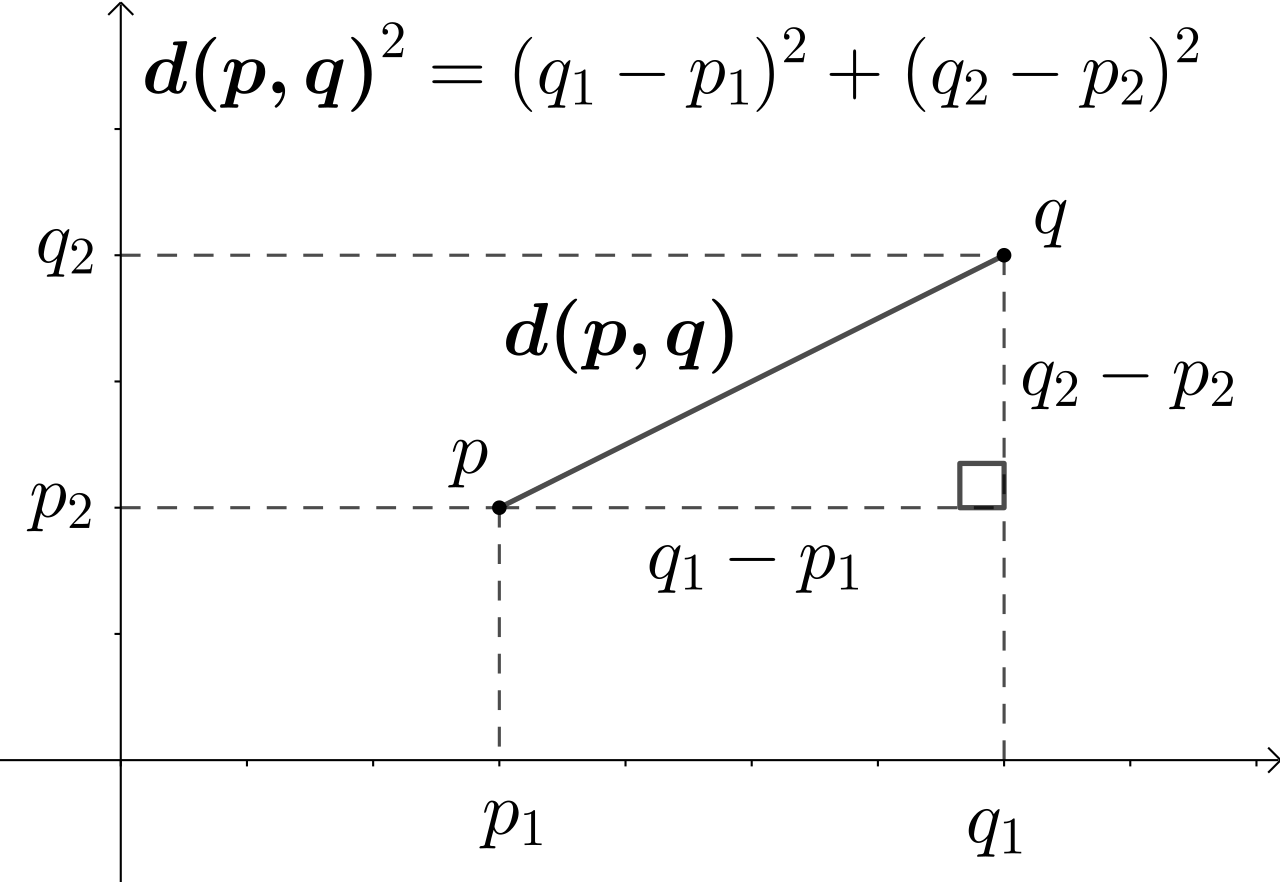

In [76]:
nome_musica = 'Taylor Swift - Blank Space'

In [77]:
cluster = projetion_kmeans.filter(projetion_kmeans.artists_song == nome_musica)
cluster

DataFrame[valence: double, year: int, acousticness: double, artists: string, danceability: double, duration_ms: int, energy: double, explicit: int, id: string, instrumentalness: double, key: int, liveness: double, loudness: double, mode: int, name: string, popularity: int, speechiness: double, tempo: double, artists_song: string, features: vector, features_scaled: vector, pca_features: vector, cluster_pca: int, x: double, y: double]

In [78]:
cluster = projetion_kmeans.filter(projetion_kmeans.artists_song == nome_musica).select('cluster_pca').collect()[0][0]
cluster

3

In [79]:
musicas_recomendadas = projetion_kmeans.filter(projetion_kmeans.cluster_pca == cluster)\
                                       .select('artists_song', 'id', 'pca_features')
musicas_recomendadas.show()


+--------------------+--------------------+--------------------+
|        artists_song|                  id|        pca_features|
+--------------------+--------------------+--------------------+
|Usher - Yeah! (fe...|5rb9QrpfcKFHM1EUb...|[-36.050436933493...|
|Kelly Clarkson - ...|3xrn9i8zhNZsTtcoW...|[-35.191226411336...|
| Keyshia Cole - Love|0W4NhJhcqKCqEP2GI...|[-34.751332435196...|
|Mariah Carey - We...|3LmvfNUQtglbTryds...|[-35.144610288312...|
|Korn - Coming Undone|6p2liQLGoDaLXgND6...|[-35.272207170621...|
|Chris Brown - Yo ...|7DFnq8FYhHMCylykf...|[-35.112344117719...|
|  Aventura - Un Beso|1SaEt8dwTuLDzenUu...|[-34.134357732463...|
|Chris Brown - Say...|5F7IJrXD6Fa3EmqoY...|[-34.728839526520...|
|Red Hot Chili Pep...|10Nmj3JCNoMeBQ87u...|[-36.101793760083...|
|Craig Morgan - In...|0Ta3jOf8m9yCSWMVw...|[-35.227552248025...|
|Arctic Monkeys - ...|3geFzA6VBSNZUTmV3...|[-34.696049351615...|
|Arctic Monkeys - 505|58ge6dfP91o9oXMzq...|[-35.057671072817...|
|T-Pain - Buy U a ...|2aI

In [80]:
componentes_musica = musicas_recomendadas.filter(musicas_recomendadas.artists_song == nome_musica)\
                                          .select('pca_features').collect()[0][0]
componentes_musica

DenseVector([-35.461, -166.9658, -12.7925, -137.9457, -13.1234, 4.1374])

In [81]:
from scipy.spatial.distance import euclidean
from pyspark.sql.types import FloatType

def calcula_distance(value):
  return euclidean(componentes_musica, value)

udf_calcula_distance = f.udf(calcula_distance, FloatType())

musicas_recomendadas_dist = musicas_recomendadas.withColumn('Dist', udf_calcula_distance('pca_features'))

musicas_recomendadas_dist.show()

+--------------------+--------------------+--------------------+----------+
|        artists_song|                  id|        pca_features|      Dist|
+--------------------+--------------------+--------------------+----------+
|Usher - Yeah! (fe...|5rb9QrpfcKFHM1EUb...|[-36.050436933493...| 0.9969399|
|Kelly Clarkson - ...|3xrn9i8zhNZsTtcoW...|[-35.191226411336...| 1.8042403|
| Keyshia Cole - Love|0W4NhJhcqKCqEP2GI...|[-34.751332435196...| 1.1707921|
|Mariah Carey - We...|3LmvfNUQtglbTryds...|[-35.144610288312...| 1.8484195|
|Korn - Coming Undone|6p2liQLGoDaLXgND6...|[-35.272207170621...| 1.1163834|
|Chris Brown - Yo ...|7DFnq8FYhHMCylykf...|[-35.112344117719...| 1.8231457|
|  Aventura - Un Beso|1SaEt8dwTuLDzenUu...|[-34.134357732463...| 1.9470732|
|Chris Brown - Say...|5F7IJrXD6Fa3EmqoY...|[-34.728839526520...| 1.4821616|
|Red Hot Chili Pep...|10Nmj3JCNoMeBQ87u...|[-36.101793760083...| 2.2942324|
|Craig Morgan - In...|0Ta3jOf8m9yCSWMVw...|[-35.227552248025...| 1.5641632|
|Arctic Monk

### Criando função Recomendador

In [82]:
def recomendador(nome_musica):
  cluster = projetion_kmeans.filter(projetion_kmeans.artists_song == nome_musica).select('cluster_pca').collect()[0][0]
  musicas_recomendadas = projetion_kmeans.filter(projetion_kmeans.cluster_pca == cluster)\
                                       .select('artists_song', 'id', 'pca_features')
  componentes_musica = musicas_recomendadas.filter(musicas_recomendadas.artists_song == nome_musica)\
                                          .select('pca_features').collect()[0][0]

  def calcula_distance(value):
    return euclidean(componentes_musica, value)

  udf_calcula_distance = f.udf(calcula_distance, FloatType())

  musicas_recomendadas_dist = musicas_recomendadas.withColumn('Dist', udf_calcula_distance('pca_features'))

  recomendadas = spark.createDataFrame(musicas_recomendadas_dist.sort('Dist').take(10)).select(['artists_song', 'id', 'Dist'])

  recomendadas.select('artists_song').show(truncate=False)


In [83]:
recomendador('Taylor Swift - Blank Space')

+-----------------------------------------+
|artists_song                             |
+-----------------------------------------+
|Taylor Swift - Blank Space               |
|Imagine Dragons - Machine                |
|The All-American Rejects - Gives You Hell|
|Darius Rucker - Beers And Sunshine       |
|Old Dominion - Snapback                  |
|Dan + Shay - Nothin' Like You            |
|Twenty One Pilots - Not Today            |
|Jon Bellion - Morning In America         |
|Kip Moore - More Girls Like You          |
|Calibre 50 - Corrido De Juanito          |
+-----------------------------------------+



In [84]:
#Função para verificar se a música existe na base de dados
def encontra_musica(nome_musica, projetion_kmeans):
  resultado = projetion_kmeans.filter(projetion_kmeans.artists_song == nome_musica).collect()
  if len(resultado) == 0:
    return False
  return True

In [85]:
encontra_musica('Old Dominion - Snapbak', projetion_kmeans)

False

## API Spotify

In [86]:
import spotipy
from spotipy.oauth2 import SpotifyOAuth, SpotifyClientCredentials

In [87]:
scope = "user-library-read playlist-modify-private"

OAuth = SpotifyOAuth(
        scope=scope,         
        redirect_uri='http://localhost:5000/callback',
        client_id = '***REMOVED***',
        client_secret = '***REMOVED***')


In [88]:
client_credentials_manager = SpotifyClientCredentials(client_id = '***REMOVED***',
                                                      client_secret = '***REMOVED***')

sp = spotipy.Spotify(client_credentials_manager = client_credentials_manager)


#### Testar requisição

In [89]:
id = projetion_kmeans.filter(projetion_kmeans.artists_song == nome_musica).select('id').collect()[0][0]
id

'1p80LdxRV74UKvL8gnD7ky'

In [90]:
sp.track(id)

{'album': {'album_type': 'album',
  'artists': [{'external_urls': {'spotify': 'https://open.spotify.com/artist/06HL4z0CvFAxyc27GXpf02'},
    'href': 'https://api.spotify.com/v1/artists/06HL4z0CvFAxyc27GXpf02',
    'id': '06HL4z0CvFAxyc27GXpf02',
    'name': 'Taylor Swift',
    'type': 'artist',
    'uri': 'spotify:artist:06HL4z0CvFAxyc27GXpf02'}],
  'available_markets': ['CA', 'US'],
  'external_urls': {'spotify': 'https://open.spotify.com/album/2QJmrSgbdM35R67eoGQo4j'},
  'href': 'https://api.spotify.com/v1/albums/2QJmrSgbdM35R67eoGQo4j',
  'id': '2QJmrSgbdM35R67eoGQo4j',
  'images': [{'height': 640,
    'url': 'https://i.scdn.co/image/ab67616d0000b2739abdf14e6058bd3903686148',
    'width': 640},
   {'height': 300,
    'url': 'https://i.scdn.co/image/ab67616d00001e029abdf14e6058bd3903686148',
    'width': 300},
   {'height': 64,
    'url': 'https://i.scdn.co/image/ab67616d000048519abdf14e6058bd3903686148',
    'width': 64}],
  'name': '1989',
  'release_date': '2014-10-27',
  'release

## Criando Recomendador

In [93]:
import matplotlib.pyplot as plt
from skimage import io

In [94]:
#Valida se a musica existe na base de dados
def encontra_musica(nome_musica, projetion_kmeans):
  resultado = projetion_kmeans.filter(projetion_kmeans.artists_song == nome_musica).collect()
  if len(resultado) == 0:
    return False
  return True

#define o calculo da distancia euclidiana
def distancia(value):
    return euclidean(componentes_musica, value)

#Calcula a distancia euclidiana para cada música do cluster e seleciona o top 10
def calcula_distâncias(nome_musica, projetion_kmeans):
  cluster = projetion_kmeans\
            .filter(projetion_kmeans.artists_song == nome_musica)\
            .select('cluster_pca').collect()[0][0]

  musicas_recomendadas = projetion_kmeans\
          .filter(projetion_kmeans.cluster_pca == cluster)\
          .select(['x', 'y', 'artists_song', 'id', 'pca_features'])

  componentes_musica = musicas_recomendadas.filter(projetion_kmeans.artists_song == nome_musica).select('pca_features').collect()[0][0]

  udfsomefunc = f.udf(distancia, FloatType())

  musicas_recomendadas_dist = musicas_recomendadas.withColumn("Dist", udfsomefunc("pca_features"))

  recomendada = spark.createDataFrame(musicas_recomendadas_dist.sort('Dist').take(10)).select('Dist', 'artists_song', 'id')

  return recomendada

#Enriquece a base com a API do Spotify
def pegar_info_api(recomendada):

  playlist_id = recomendada.select('id').collect()

  url = []
  name = []
  url_musica = []

  for i in playlist_id:
      track = sp.track(i[0])
      url.append(track["album"]["images"][1]["url"])
      url_musica.append(track["external_urls"]['spotify'])
      name.append(track["name"])

  return url, name, url_musica

#Apresenta os resultados na tela
def plotando_resultado(url, name, url_musica):
    plt.figure(figsize=(15,10))
    columns = 5
    for i, u in enumerate(url):
        ax = plt.subplot(len(url) // columns + 1, columns, i + 1)
        image = io.imread(u)
        plt.imshow(image)
        ax.get_yaxis().set_visible(False)
        plt.xticks(color = 'w', fontsize = 0.1)
        plt.yticks(color = 'w', fontsize = 0.1)
        plt.xlabel(name[i], fontsize = 10)
        plt.tight_layout(h_pad=0.7, w_pad=0)
        plt.subplots_adjust(wspace=None, hspace=None)
        plt.grid(visible=None)
    plt.show()

#Realiza a recomendação de 10 músicas baseadas em uma busca
def recomendador(nome_musica, projetion_kmeans):

  if encontra_musica(nome_musica, projetion_kmeans) == False:
    print('Musica ainda não disponivel no recomendador')
    return None
  
  recomendada = calcula_distâncias(nome_musica, projetion_kmeans)
  url, name, url_musica = pegar_info_api(recomendada)
  plotando_resultado(url, name, url_musica)

  return {'nomes': name, 'URLs': url_musica}

C:\Users\galgu\AppData\Local\Temp\ipykernel_15520\3464347828.py:57: UserWarning:

The figure layout has changed to tight



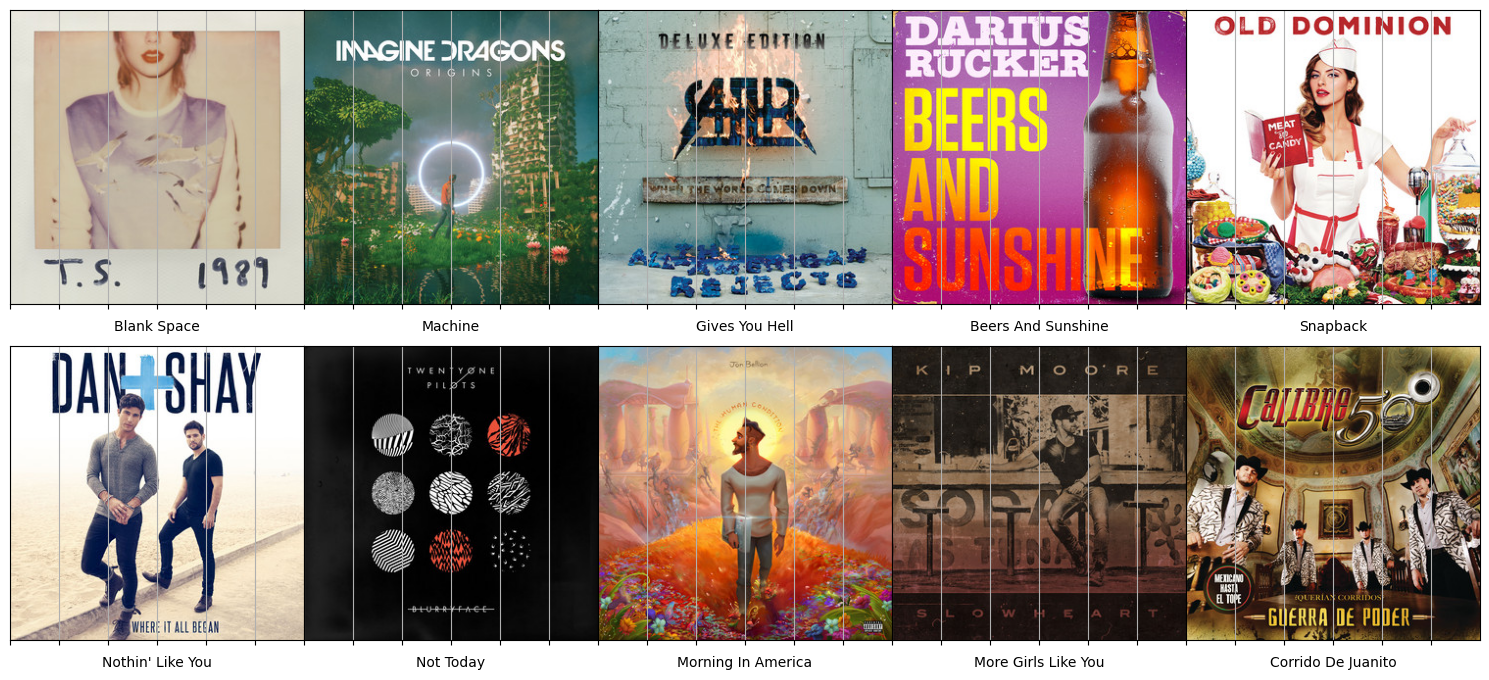

{'nomes': ['Blank Space',
  'Machine',
  'Gives You Hell',
  'Beers And Sunshine',
  'Snapback',
  "Nothin' Like You",
  'Not Today',
  'Morning In America',
  'More Girls Like You',
  'Corrido De Juanito'],
 'URLs': ['https://open.spotify.com/track/1p80LdxRV74UKvL8gnD7ky',
  'https://open.spotify.com/track/4uGY9CqDtGtaTTLg1cgsWD',
  'https://open.spotify.com/track/6ihL9TjfRjadfEePzXXyVF',
  'https://open.spotify.com/track/36ISlLb12gKuCCVTYXC0gb',
  'https://open.spotify.com/track/7I5fYc4qKJddht8Ozhqqdx',
  'https://open.spotify.com/track/4W38RXuQNuoTSwVsQA1OGC',
  'https://open.spotify.com/track/7qxjGHW485TL8ciwkHD5MK',
  'https://open.spotify.com/track/2JXNOtb0ANe6MzgRYDQG2J',
  'https://open.spotify.com/track/73WWkaWkIRSP3MYGZ14aY4',
  'https://open.spotify.com/track/0ehx1p1HMn7NMKisZaO9oL']}

In [95]:
recomendador('Taylor Swift - Blank Space', projetion_kmeans)